# Dispersion-assisted phase retrieval: what Lean proves, and what it doesn't

The forward model is H_D(ν) = exp(iπDν²), Jalali's time stretch. Measure two intensities
|H_{D1}E|² and |H_{D2}E|², then alternate projections between them (Gerchberg-Saxton).
Each step below has a **Lean theorem** (machine-checked) and a **numerical check** on the real
`dgs/gs_core.py` code.

| # | Claim | Lean | Numerics |
|---|---|---|---|
| 1 | phase'' = 2πD (D is the group-delay dispersion) | `phase_second_deriv` | SymPy |
| 2 | \|H\| = 1, so energy is conserved | `H_norm`, `energy_conserved` | Parseval on the FFT |
| 3 | H_{D1}H_{D2} = H_{D1+D2}, and undisperse inverts disperse | `H_add`, `H_inverse` | round trip ≈ 1e-16 |
| 4 | unitary steps preserve distance | `dist_preserved` | |
| 5 | the amplitude projection is the **nearest** point | `amplitude_projection_nearest` | random trials |
| 6 | the constraint set is **not convex** | `magnitude_set_not_convex` | midpoint of 1 and −1 |
| 7 | alternating nearest-point projections never increase the gap | `error_nonincreasing` | plain GS, measured |

**Not proved:** that GS reaches the *true* phase (uniqueness), anything about noise, or the
extra unit-amplitude step. §7 shows numerically that this extra step breaks the guarantee.

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()))
import numpy as np, sympy as sp, pandas as pd, matplotlib.pyplot as plt
from IPython.display import display
sp.init_printing(use_unicode=True)
from dgs import gs_core as G
N, D1, D2 = 256, -5000.0, -5750.0
k = np.arange(N)
E_true = np.exp(1j * np.pi / 2 * np.mod(k // 8 * 7 + 3, 4))       # QPSK-like test field
I1, I2 = np.abs(G.disperse(E_true, D1))**2, np.abs(G.disperse(E_true, D2))**2

In [2]:
%load_ext dgs.lean_magic
%lean_reset

Lean cells cleared.


In [3]:
%%lean header
/-
Dispersion-assisted Gerchberg-Saxton phase retrieval: the machine-checkable pieces. Lean 4 + Mathlib.
Companion to notebooks/dispersion_phase_retrieval_lean.ipynb and dgs/gs_core.py.

The forward model (Jalali's time stretch): at each frequency nu the field is multiplied by
H_D(nu) = exp(i pi D nu^2). GS alternates between two measured intensities |H_D1 E|^2 and |H_D2 E|^2.

What is proved here:
  1. The dispersion phase pi D nu^2 has second derivative 2 pi D: D is the group-delay dispersion
  2. |H_D(nu)| = 1: dispersion changes only phase, so it conserves energy at every frequency
  3. Dispersion is a group: H_D1 H_D2 = H_(D1+D2) and H_D H_(-D) = 1 (undisperse inverts disperse)
  4. Unitary => distances are preserved: |H x - H y| = |x - y|
  5. The amplitude projection z -> a z/|z| is the NEAREST point with magnitude a
  6. The magnitude set {|z| = a} is not convex (midpoint of 1 and -1 is 0): why GS can stagnate
  7. Alternating nearest-point projections never increase the gap between the two sets
     (Fienup's error-reduction argument), stated for any metric space

What is NOT proved here: that GS converges to the TRUE phase (uniqueness), or anything about
noise. Item 7 assumes each step is an exact nearest-point projection; the extra unit-amplitude
step in gs_core.gs_iteration(unit_amplitude=True) adds a third projection that item 7 does not cover.

Check with (from a Lake project that depends on Mathlib):
    lake env lean DispersionPhaseRetrieval.lean
-/
import Mathlib.Analysis.SpecialFunctions.Complex.Circle
import Mathlib.Analysis.SpecialFunctions.Pow.Deriv
import Mathlib.Analysis.Calculus.Deriv.Pow
import Mathlib.Topology.MetricSpace.Basic
import Mathlib.Tactic.LinearCombination
import Mathlib.Tactic.FieldSimp

open Complex

namespace DAPR

/-- The dispersion transfer function H_D(nu) = exp(i pi D nu^2). -/
noncomputable def H (D ν : ℝ) : ℂ := exp (((Real.pi * D * ν ^ 2 : ℝ) : ℂ) * I)

**Lean cell `header`** (collected; compiled by `%lean_check`)
```lean
/-
Dispersion-assisted Gerchberg-Saxton phase retrieval: the machine-checkable pieces. Lean 4 + Mathlib.
Companion to notebooks/dispersion_phase_retrieval_lean.ipynb and dgs/gs_core.py.

The forward model (Jalali's time stretch): at each frequency nu the field is multiplied by
H_D(nu) = exp(i pi D nu^2). GS alternates between two measured intensities |H_D1 E|^2 and |H_D2 E|^2.

What is proved here:
  1. The dispersion phase pi D nu^2 has second derivative 2 pi D: D is the group-delay dispersion
  2. |H_D(nu)| = 1: dispersion changes only phase, so it conserves energy at every frequency
  3. Dispersion is a group: H_D1 H_D2 = H_(D1+D2) and H_D H_(-D) = 1 (undisperse inverts disperse)
  4. Unitary => distances are preserved: |H x - H y| = |x - y|
  5. The amplitude projection z -> a z/|z| is the NEAREST point with magnitude a
  6. The magnitude set {|z| = a} is not convex (midpoint of 1 and -1 is 0): why GS can stagnate
  7. Alternating nearest-point projections never increase the gap between the two sets
     (Fienup's error-reduction argument), stated for any metric space

What is NOT proved here: that GS converges to the TRUE phase (uniqueness), or anything about
noise. Item 7 assumes each step is an exact nearest-point projection; the extra unit-amplitude
step in gs_core.gs_iteration(unit_amplitude=True) adds a third projection that item 7 does not cover.

Check with (from a Lake project that depends on Mathlib):
    lake env lean DispersionPhaseRetrieval.lean
-/
import Mathlib.Analysis.SpecialFunctions.Complex.Circle
import Mathlib.Analysis.SpecialFunctions.Pow.Deriv
import Mathlib.Analysis.Calculus.Deriv.Pow
import Mathlib.Topology.MetricSpace.Basic
import Mathlib.Tactic.LinearCombination
import Mathlib.Tactic.FieldSimp

open Complex

namespace DAPR

/-- The dispersion transfer function H_D(nu) = exp(i pi D nu^2). -/
noncomputable def H (D ν : ℝ) : ℂ := exp (((Real.pi * D * ν ^ 2 : ℝ) : ℂ) * I)
```

## 1. Second derivative of the phase

φ(ν) = πDν², so φ'' = 2πD. In fiber optics that constant is the group-delay dispersion.
Dispersion works by giving each frequency a different delay, τ(ν) = φ'(ν)/2π = Dν.
**Diffraction is the same math in space:** Fresnel propagation multiplies the spatial
spectrum by exp(−iπλz f_x²), the same quadratic phase. This is space-time duality, and it's why
"dispersion-assisted" phase retrieval mirrors the classic defocus-diversity method in imaging.

In [4]:
nu, D, lam, z, fx = sp.symbols("nu D lambda z f_x", real=True)
phi = sp.pi * D * nu**2
display(sp.Eq(sp.Symbol("phi''"), sp.diff(phi, nu, 2)))
display(sp.Eq(sp.Symbol("H_fresnel"), sp.exp(-sp.I * sp.pi * lam * z * fx**2)))
print("time stretch <-> diffraction:  D  <->  -lambda z")

time stretch <-> diffraction:  D  <->  -lambda z


In [5]:
%%lean phase
/-! ## 1. The phase is quadratic: its second derivative is 2 pi D -/

theorem phase_hasDerivAt (D ν : ℝ) :
    HasDerivAt (fun ν => Real.pi * D * ν ^ 2) (2 * Real.pi * D * ν) ν := by
  have h := (hasDerivAt_pow 2 ν).const_mul (Real.pi * D)
  refine h.congr_deriv ?_
  norm_num
  ring

theorem phase_second_deriv (D ν : ℝ) :
    deriv (deriv (fun ν => Real.pi * D * ν ^ 2)) ν = 2 * Real.pi * D := by
  have hd : deriv (fun ν => Real.pi * D * ν ^ 2) = fun ν => 2 * Real.pi * D * ν := by
    funext x; exact (phase_hasDerivAt D x).deriv
  rw [hd]
  have h := (hasDerivAt_id ν).const_mul (2 * Real.pi * D)
  simp

**Lean cell `phase`** (collected; compiled by `%lean_check`)
```lean
/-! ## 1. The phase is quadratic: its second derivative is 2 pi D -/

theorem phase_hasDerivAt (D ν : ℝ) :
    HasDerivAt (fun ν => Real.pi * D * ν ^ 2) (2 * Real.pi * D * ν) ν := by
  have h := (hasDerivAt_pow 2 ν).const_mul (Real.pi * D)
  refine h.congr_deriv ?_
  norm_num
  ring

theorem phase_second_deriv (D ν : ℝ) :
    deriv (deriv (fun ν => Real.pi * D * ν ^ 2)) ν = 2 * Real.pi * D := by
  have hd : deriv (fun ν => Real.pi * D * ν ^ 2) = fun ν => 2 * Real.pi * D * ν := by
    funext x; exact (phase_hasDerivAt D x).deriv
  rw [hd]
  have h := (hasDerivAt_id ν).const_mul (2 * Real.pi * D)
  simp
```

## 2–4. Unit modulus, composition, inversion, distances

In [6]:
Ed = G.disperse(E_true, D1)
print("Parseval: energy after / before =", np.sum(abs(Ed)**2) / np.sum(abs(E_true)**2))
print("undisperse(disperse(E)) - E, max =", np.max(abs(G.undisperse(Ed, D1) - E_true)))
print("disperse(disperse(E, D1), D2) vs disperse(E, D1 + D2), max diff =",
      np.max(abs(G.disperse(G.disperse(E_true, D1), D2) - G.disperse(E_true, D1 + D2))))
y = np.exp(1j * np.random.default_rng(0).uniform(0, 2 * np.pi, N))
print("|Hx - Hy| / |x - y| =", np.linalg.norm(G.disperse(E_true, D1) - G.disperse(y, D1)) / np.linalg.norm(E_true - y))

Parseval: energy after / before = 0.9999999999999998
undisperse(disperse(E)) - E, max = 5.03305484502932e-16
disperse(disperse(E, D1), D2) vs disperse(E, D1 + D2), max diff = 2.4331971232205444e-13
|Hx - Hy| / |x - y| = 1.0


In [7]:
%%lean unit
/-! ## 2. Unit modulus: energy is conserved at every frequency -/

theorem H_norm (D ν : ℝ) : ‖H D ν‖ = 1 := by
  unfold H
  exact norm_exp_ofReal_mul_I _

theorem energy_conserved (D ν : ℝ) (X : ℂ) : ‖H D ν * X‖ = ‖X‖ := by
  rw [norm_mul, H_norm, one_mul]

**Lean cell `unit`** (collected; compiled by `%lean_check`)
```lean
/-! ## 2. Unit modulus: energy is conserved at every frequency -/

theorem H_norm (D ν : ℝ) : ‖H D ν‖ = 1 := by
  unfold H
  exact norm_exp_ofReal_mul_I _

theorem energy_conserved (D ν : ℝ) (X : ℂ) : ‖H D ν * X‖ = ‖X‖ := by
  rw [norm_mul, H_norm, one_mul]
```

In [8]:
%%lean group
/-! ## 3. Dispersion composes and inverts -/

theorem H_add (D1 D2 ν : ℝ) : H D1 ν * H D2 ν = H (D1 + D2) ν := by
  unfold H
  rw [← exp_add]
  congr 1
  push_cast
  ring

theorem H_inverse (D ν : ℝ) : H D ν * H (-D) ν = 1 := by
  rw [H_add, add_neg_cancel]
  unfold H
  simp

**Lean cell `group`** (collected; compiled by `%lean_check`)
```lean
/-! ## 3. Dispersion composes and inverts -/

theorem H_add (D1 D2 ν : ℝ) : H D1 ν * H D2 ν = H (D1 + D2) ν := by
  unfold H
  rw [← exp_add]
  congr 1
  push_cast
  ring

theorem H_inverse (D ν : ℝ) : H D ν * H (-D) ν = 1 := by
  rw [H_add, add_neg_cancel]
  unfold H
  simp
```

In [9]:
%%lean distance
/-! ## 4. Unitary steps preserve distances -/

theorem dist_preserved (D ν : ℝ) (x y : ℂ) : ‖H D ν * x - H D ν * y‖ = ‖x - y‖ := by
  rw [← mul_sub, energy_conserved]

**Lean cell `distance`** (collected; compiled by `%lean_check`)
```lean
/-! ## 4. Unitary steps preserve distances -/

theorem dist_preserved (D ν : ℝ) (x y : ℂ) : ‖H D ν * x - H D ν * y‖ = ‖x - y‖ := by
  rw [← mul_sub, energy_conserved]
```

## 5. The amplitude projection is the nearest point

`apply_amplitude_constraint` replaces |z| with the measured a and keeps the phase. Lean proves
no other point with magnitude a is closer to z. The proof is the reverse triangle inequality:
|z − w| ≥ ||z| − |w|| = ||z| − a|, which is exactly the distance to a·z/|z|.

In [10]:
rng = np.random.default_rng(1)
worst = np.inf
for _ in range(20000):
    zc = complex(*rng.normal(size=2)); a = rng.uniform(0, 3)
    proj = a * zc / abs(zc)
    w = a * np.exp(1j * rng.uniform(0, 2 * np.pi))
    worst = min(worst, abs(zc - w) - abs(zc - proj))
print("min over 20000 random trials of |z - w| - |z - P(z)| =", worst, "(never negative)")

min over 20000 random trials of |z - w| - |z - P(z)| = 2.9633078657553824e-08 (never negative)


In [11]:
%%lean projection
/-! ## 5. The amplitude projection is the nearest point on the circle |w| = a -/

theorem amplitude_projection_nearest (z w : ℂ) (a : ℝ) (hz0 : z ≠ 0) (hw : ‖w‖ = a) :
    ‖z - ((a / ‖z‖ : ℝ) : ℂ) * z‖ ≤ ‖z - w‖ := by
  have hz : 0 < ‖z‖ := norm_pos_iff.mpr hz0
  have h1 : z - ((a / ‖z‖ : ℝ) : ℂ) * z = ((1 - a / ‖z‖ : ℝ) : ℂ) * z := by
    push_cast; ring
  have h2 : |1 - a / ‖z‖| * ‖z‖ = |‖z‖ - a| := by
    rw [← abs_of_pos hz, ← abs_mul, abs_of_pos hz, sub_mul, div_mul_cancel₀ _ hz.ne', one_mul]
  rw [h1, norm_mul, Complex.norm_real, Real.norm_eq_abs, h2, ← hw]
  exact abs_norm_sub_norm_le z w

theorem projection_has_magnitude (z : ℂ) (a : ℝ) (hz0 : z ≠ 0) (ha : 0 ≤ a) :
    ‖((a / ‖z‖ : ℝ) : ℂ) * z‖ = a := by
  have hz : 0 < ‖z‖ := norm_pos_iff.mpr hz0
  rw [norm_mul, Complex.norm_real, Real.norm_eq_abs, abs_of_nonneg (div_nonneg ha hz.le),
    div_mul_cancel₀ _ hz.ne']

**Lean cell `projection`** (collected; compiled by `%lean_check`)
```lean
/-! ## 5. The amplitude projection is the nearest point on the circle |w| = a -/

theorem amplitude_projection_nearest (z w : ℂ) (a : ℝ) (hz0 : z ≠ 0) (hw : ‖w‖ = a) :
    ‖z - ((a / ‖z‖ : ℝ) : ℂ) * z‖ ≤ ‖z - w‖ := by
  have hz : 0 < ‖z‖ := norm_pos_iff.mpr hz0
  have h1 : z - ((a / ‖z‖ : ℝ) : ℂ) * z = ((1 - a / ‖z‖ : ℝ) : ℂ) * z := by
    push_cast; ring
  have h2 : |1 - a / ‖z‖| * ‖z‖ = |‖z‖ - a| := by
    rw [← abs_of_pos hz, ← abs_mul, abs_of_pos hz, sub_mul, div_mul_cancel₀ _ hz.ne', one_mul]
  rw [h1, norm_mul, Complex.norm_real, Real.norm_eq_abs, h2, ← hw]
  exact abs_norm_sub_norm_le z w

theorem projection_has_magnitude (z : ℂ) (a : ℝ) (hz0 : z ≠ 0) (ha : 0 ≤ a) :
    ‖((a / ‖z‖ : ℝ) : ℂ) * z‖ = a := by
  have hz : 0 < ‖z‖ := norm_pos_iff.mpr hz0
  rw [norm_mul, Complex.norm_real, Real.norm_eq_abs, abs_of_nonneg (div_nonneg ha hz.le),
    div_mul_cancel₀ _ hz.ne']
```

## 6. Midpoint: the magnitude set is not convex

The midpoint of 1 and −1 is 0, which isn't on the unit circle. Projections onto **convex** sets
always converge to a common point when one exists. The magnitude sets aren't convex, so GS has
no such guarantee: it can stall in a wrong answer. That's why the dispersion pair needs enough
diversity (|D| ≥ 5000 in this repo's experiments).

In [12]:
%%lean nonconvex
/-! ## 6. The magnitude constraint set is not convex (midpoint in linear algebra) -/

theorem magnitude_set_not_convex :
    ∃ x y : ℂ, ‖x‖ = 1 ∧ ‖y‖ = 1 ∧ ‖(x + y) / 2‖ ≠ 1 := by
  refine ⟨1, -1, by simp, by simp, ?_⟩
  simp

**Lean cell `nonconvex`** (collected; compiled by `%lean_check`)
```lean
/-! ## 6. The magnitude constraint set is not convex (midpoint in linear algebra) -/

theorem magnitude_set_not_convex :
    ∃ x y : ℂ, ‖x‖ = 1 ∧ ‖y‖ = 1 ∧ ‖(x + y) / 2‖ ≠ 1 := by
  refine ⟨1, -1, by simp, by simp, ?_⟩
  simp
```

## 7. Error reduction: what the theorem guarantees, measured

Let x_k be on set B (consistent with I₂) and a_k = P_A(x_k) the nearest point on set A
(consistent with I₁). Because x_{k+1} = P_B(a_k) is a nearest point, the gap
‖x_k − a_k‖ can never grow. **Plain GS** (two projections) obeys this exactly.
`gs_iteration(unit_amplitude=True)` adds a third projection onto |E| = 1, which the theorem
doesn't cover. Its intensity error can go up, and here it does.

plain GS: largest increase of the gap = -2.653692001253205e-06 (<= 0 up to rounding)


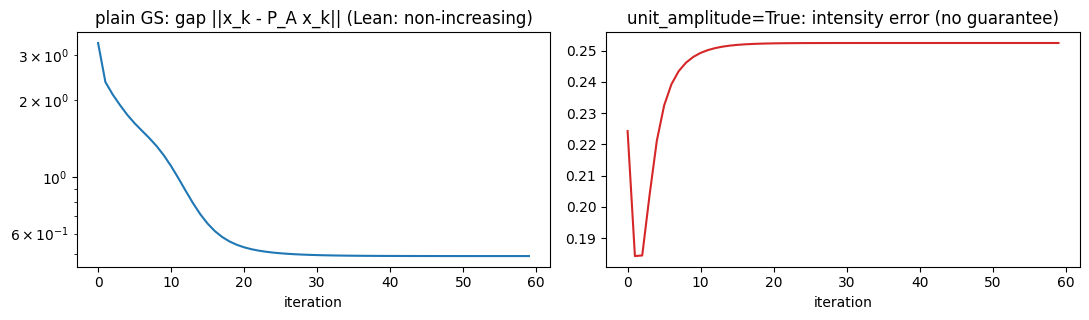

In [13]:
PA = lambda E: G.undisperse(np.sqrt(I1) * np.exp(1j * np.angle(G.disperse(E, D1))), D1)
PB = lambda E: G.undisperse(np.sqrt(I2) * np.exp(1j * np.angle(G.disperse(E, D2))), D2)
x = PB(G.undisperse(np.sqrt(I1).astype(complex), D1))
gaps = []
for _ in range(60):
    a = PA(x); gaps.append(np.linalg.norm(x - a)); x = PB(a)
gaps = np.array(gaps)
print("plain GS: largest increase of the gap =", np.max(np.diff(gaps)), "(<= 0 up to rounding)")
E = G.undisperse(np.sqrt(I1).astype(complex), D1); ua = []
for _ in range(60):
    E = G.gs_iteration(E, I1, I2, D1, D2, unit_amplitude=True)
    ua.append(np.sqrt(np.mean((np.abs(G.disperse(E, D2))**2 - I2)**2)))
fig, ax = plt.subplots(1, 2, figsize=(11, 3.3))
ax[0].semilogy(gaps); ax[0].set(title="plain GS: gap ||x_k - P_A x_k|| (Lean: non-increasing)", xlabel="iteration")
ax[1].plot(ua, "C3"); ax[1].set(title="unit_amplitude=True: intensity error (no guarantee)", xlabel="iteration")
plt.tight_layout(); plt.show()

In [14]:
%%lean error_reduction
/-! ## 7. Alternating projections: the gap never grows (error reduction) -/

/-- x ∈ B, a ∈ A; x' is a nearest point of B to a, and a' is a nearest point of A to x'.
Then the new gap dist x' a' is at most the old gap dist x a. -/
theorem error_nonincreasing {X : Type*} [MetricSpace X] (A B : Set X) (x a x' a' : X)
    (hx : x ∈ B) (ha : a ∈ A)
    (hB : ∀ y ∈ B, dist x' a ≤ dist y a) (hA : ∀ z ∈ A, dist x' a' ≤ dist x' z) :
    dist x' a' ≤ dist x a :=
  calc dist x' a' ≤ dist x' a := hA a ha
    _ ≤ dist x a := hB x hx

**Lean cell `error_reduction`** (collected; compiled by `%lean_check`)
```lean
/-! ## 7. Alternating projections: the gap never grows (error reduction) -/

/-- x ∈ B, a ∈ A; x' is a nearest point of B to a, and a' is a nearest point of A to x'.
Then the new gap dist x' a' is at most the old gap dist x a. -/
theorem error_nonincreasing {X : Type*} [MetricSpace X] (A B : Set X) (x a x' a' : X)
    (hx : x ∈ B) (ha : a ∈ A)
    (hB : ∀ y ∈ B, dist x' a ≤ dist y a) (hA : ∀ z ∈ A, dist x' a' ≤ dist x' z) :
    dist x' a' ≤ dist x a :=
  calc dist x' a' ≤ dist x' a := hA a ha
    _ ≤ dist x a := hB x hx
```

## 8. The same pipeline in MATLAB

`matlab/mp_toolkit.m` reimplements the box energies, the finite-difference Schrödinger solver,
tunneling, dispersion, and this GS loop. `tests/test_matlab_toolkit.py` checks that MATLAB R2025b
agrees with Python (box and tunneling to 1e-6, the GS error history to 1e-6).

In [15]:
import glob, json, shutil, subprocess, tempfile
exe = shutil.which("matlab") or (sorted(glob.glob(r"C:\Program Files\MATLAB\R20*\bin\matlab.exe")) or [None])[-1]
root = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if exe:
    out = Path(tempfile.gettempdir()) / "mp_toolkit_nb.json"
    subprocess.run([exe, "-batch", f"addpath('{(root / 'matlab').as_posix()}'); mp_toolkit('{out.as_posix()}')"],
                   capture_output=True, text=True, timeout=600)
    m = json.loads(out.read_text())
    E = G.undisperse(np.sqrt(I1).astype(complex), D1); py = []
    for _ in range(30):
        E = G.gs_iteration(E, I1, I2, D1, D2, unit_amplitude=True)
        py.append(np.sqrt(np.mean((np.abs(G.disperse(E, D2))**2 - I2)**2)))
    print("box energies (MATLAB):", np.round(m["box_E"], 4))
    print("GS error history, max |MATLAB - Python| =", np.max(np.abs(np.array(m["gs_errors"]) - py)))
else:
    print("MATLAB not installed: skipped")

box energies (MATLAB): [ 1.5041  6.0165 13.5371 24.0659]
GS error history, max |MATLAB - Python| = 6.661338147750939e-16


## 9. Compile every Lean cell

In [16]:
%%lean footer
end DAPR

**Lean cell `footer`** (collected; compiled by `%lean_check`)
```lean
end DAPR
```

In [17]:
lean_result = %lean_check
from dgs.lean_magic import SESSION
display(pd.DataFrame({"Lean theorem": SESSION.last.theorems, "status": SESSION.last.status}))

Lean status: VERIFIED  (lake env lean exit 0, no errors, no sorry), 10 s


,Lean theorem,status
0,phase_hasDerivAt,VERIFIED
1,phase_second_deriv,VERIFIED
2,H_norm,VERIFIED
3,energy_conserved,VERIFIED
4,H_add,VERIFIED
5,H_inverse,VERIFIED
6,dist_preserved,VERIFIED
7,amplitude_projection_nearest,VERIFIED
8,projection_has_magnitude,VERIFIED
9,magnitude_set_not_convex,VERIFIED
